In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats
import os
import statsmodels.formula.api as smf

import testis_model as tm

In [2]:
from analysis import small_label_settings, color_map
plt.style.use('default')
plt.rcParams.update(small_label_settings)

In [3]:
file = os.path.join('..', 'experiments', 'full_pipeline', 'final_data.csv') 
df = pd.read_csv(file)

#remove controls
df = df[~df['fish'].str.contains('fishctrl|fishwater', case=False, regex=True, na=False)]

# Convert sample number to time
df['time'] = df['sample'].map(tm.data_processing.sample_map_int)

In [4]:
# Mixed Linear Model (by CRS)

# A) Count unique barcodes per fish at each timepoint
barcode_counts_time = (
    df.groupby(['fish', 'time'])['barcode']
    .nunique()
    .reset_index(name='unique_barcode_count')
)

# Order fish numerically for legend
barcode_counts_time['fish_num'] = barcode_counts_time['fish'].str.extract(r'(\d+)').astype(int)
fish_order = sorted(barcode_counts_time['fish'].unique(), key=lambda x: int(x.replace('fish', '')))
barcode_counts_time['fish'] = pd.Categorical(barcode_counts_time['fish'], categories=fish_order, ordered=True)
barcode_counts_time.head(3)

,fish,time,unique_barcode_count,fish_num
0,fish1,5,8,1
1,fish1,6,9,1
2,fish1,9,8,1


In [5]:
# B) Function to compute Shannon diversity for a group (by CRS)
def shannon_diversity(group):
    counts = group['reads'].values
    total = counts.sum()
    if total == 0:
        return 0.0
    p = counts / total
    return -(p * np.log(p)).sum()

# Compute diversity per (fish, sample)
diversity = (
    df.groupby(['fish', 'time'])
    .apply(shannon_diversity, include_groups = False)
    .reset_index(name='diversity')
)

barcode_counts_time = barcode_counts_time.merge(diversity, on=['fish', 'time'])
barcode_counts_time.head()

,fish,time,unique_barcode_count,fish_num,diversity
0,fish1,5,8,1,1.878303
1,fish1,6,9,1,2.163849
2,fish1,9,8,1,2.101588
3,fish1,10,8,1,2.094578
4,fish1,11,7,1,1.808714


In [6]:
# Fit mixed linear model
barcode_counts_time['time_centered'] = (
    barcode_counts_time.groupby('fish_num')['time'].transform(lambda x: x - x.mean())
)

model = smf.mixedlm(
    'diversity ~ time_centered',
    data=barcode_counts_time,
    groups=barcode_counts_time['fish_num'],
    re_formula='~time_centered'   # random intercept
)
result = model.fit()
print(result.summary())

               Mixed Linear Model Regression Results
Model:                 MixedLM     Dependent Variable:     diversity
No. Observations:      242         Method:                 REML     
No. Groups:            24          Scale:                  0.0941   
Min. group size:       3           Log-Likelihood:         -119.1200
Max. group size:       17          Converged:              Yes      
Mean group size:       10.1                                         
--------------------------------------------------------------------
                          Coef.  Std.Err.   z    P>|z| [0.025 0.975]
--------------------------------------------------------------------
Intercept                  2.297    0.107 21.402 0.000  2.086  2.507
time_centered             -0.021    0.012 -1.690 0.091 -0.045  0.003
Group Var                  0.265    0.283                           
Group x time_centered Cov  0.003    0.023                           
time_centered Var          0.002    0.004         

/opt/anaconda3/envs/weber/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


In [7]:
intercept = result.params['Intercept']
slope = result.params['time_centered']

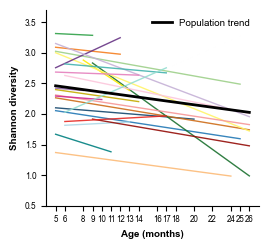

In [8]:
fig, ax = plt.subplots(figsize=(2.7, 2.5))

show_dots = False
show_grey_data_lines = False
show_individual_fits = True

# Overlay colored fitted lines for each fish (optional)
for fish, sub in barcode_counts_time.groupby("fish_num"):
    effects = result.random_effects[fish]
    ri = effects.get("Intercept", effects.get("Group", 0.0))
    rs = effects["time_centered"]
    group_mean = sub["time"].mean()
    x_vals = np.linspace(sub["time"].min(), sub["time"].max(), 100)
    x_centered = x_vals - group_mean
    y_pred = (intercept + ri) + (slope + rs) * x_centered
    ax.plot(
        x_vals, 
        y_pred, 
        color=color_map.get(f'fish{fish}', 'gray'),
        linewidth=1,
        alpha=0.9,
        zorder=2
    )

# Add overall population trendline (bold black line)
# Calculate population-level prediction across the full time range
all_times = barcode_counts_time['time'].values
overall_mean = all_times.mean()
x_range = np.linspace(all_times.min(), all_times.max(), 100)
x_centered_overall = x_range - overall_mean
y_population = intercept + slope * x_centered_overall

ax.plot(
    x_range,
    y_population,
    color='black',
    linewidth=2,
    label='Population trend',
    zorder=3
)

# Format axes
ax.set_xlabel('Age (months)', fontweight = 'bold')
ax.set_ylabel('Shannon diversity', fontweight = 'bold')
ax.set_ylim(0.5, 3.7)
ax.set_yticks([0.5, 1, 1.5, 2, 2.5, 3, 3.5])
for label in ax.get_xticklabels():
    label.set_fontname('Arial Narrow')

# Set x-axis to show all samples
all_samples = sorted(barcode_counts_time['time'].unique())
ax.set_xticks(all_samples)
ax.set_xticklabels(all_samples, fontsize=7)

ax.legend(
    title=None,
    bbox_to_anchor=(1, 1),
    loc='upper right',
    frameon=False,
    fontsize=7,
    title_fontsize=7,
    ncol=1
)

for s in ['top', 'right']:
    ax.spines[s].set_visible(False)

plt.tight_layout()

plt.savefig(os.path.join('images', 'diversity', 'diversity_model.svg'), bbox_inches='tight', transparent=True)
plt.savefig(os.path.join('images', 'diversity', 'diversity_model.png'), dpi=300, bbox_inches='tight', transparent=True)
plt.show()

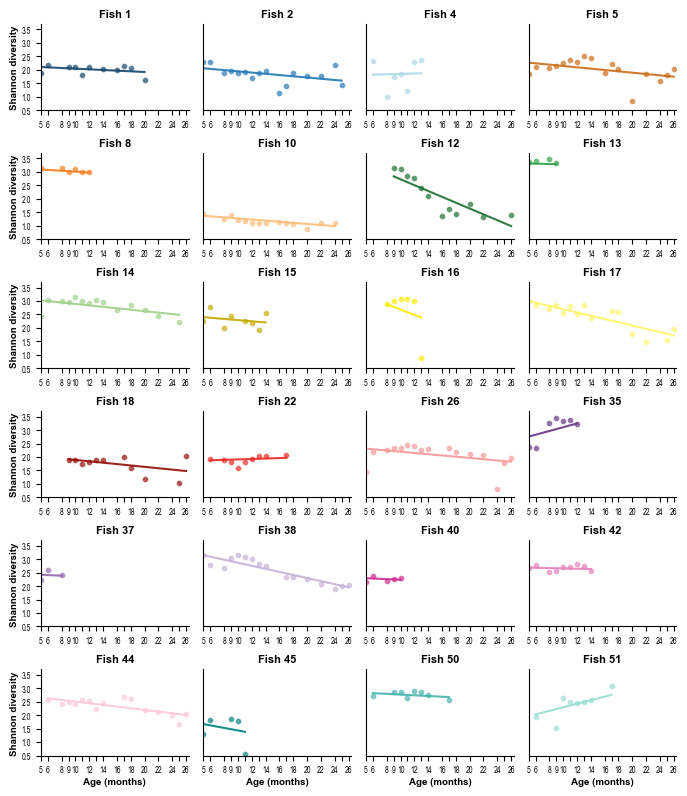

In [9]:
# Plot each fish MLM on its own facet

fish_to_plot = [1, 2, 4, 5, 8, 10, 12,
               13, 14, 15, 16, 17, 18,
               22, 26, 35, 37, 38, 40,
               42, 44, 45, 50, 51]

all_samples = sorted(barcode_counts_time['time'].unique())
x_min = min(all_samples)
x_max = max(all_samples)

facet_spacing_h = 0.1
facet_spacing_v = 0.5
label_pad = 2

# Options to toggle different elements
show_dots = True
show_grey_data_lines = False
show_individual_fits = True
show_population_trend = False

# Calculate grid dimensions
n_fish = len(fish_to_plot)
n_cols = 4
n_rows = (n_fish + n_cols - 1) // n_cols

# Create figure and subplots
fig, axes = plt.subplots(n_rows, n_cols, figsize=(8.2, 9.5))
plt.subplots_adjust(hspace=facet_spacing_v, wspace=facet_spacing_h)

# Flatten axes array for easier iteration
axes = axes.flatten() if n_fish > 1 else [axes]

# Plot each fish
for idx, fish_num in enumerate(fish_to_plot):
    ax = axes[idx]
    fish_name = f'fish{fish_num}'
    fish_data = barcode_counts_time[barcode_counts_time['fish_num'] == fish_num].sort_values('time')
    
    # Plot dots
    for _, row in fish_data.iterrows():
        ax.scatter(
            row['time'],
            row['diversity'],
            color=color_map.get(fish_name, 'gray'),
            s=18,
            alpha=0.7,
            edgecolors='white',
            linewidth=0.3,
            zorder=2
        )

    # Individual fit
    effects = result.random_effects[fish_num]
    ri = effects.get("Intercept", effects.get("Group", 0.0))
    rs = effects["time_centered"]
    group_mean = fish_data["time"].mean()
    x_vals = np.linspace(fish_data["time"].min(), fish_data["time"].max(), 100)
    x_centered = x_vals - group_mean
    y_pred = (intercept + ri) + (slope + rs) * x_centered
    ax.plot(
        x_vals, 
        y_pred, 
        color=color_map.get(fish_name, 'gray'),
        linewidth=1.5,
        alpha=0.9,
        zorder=2
    )
    
    # Format title: "Fish 1"
    ax.set_title(f'Fish {fish_num}', fontsize=8, fontweight='bold', pad=5)
    
    # Format axes with label padding
    ax.set_ylim(0.5, 3.7)
    ax.set_yticks([0.5, 1, 1.5, 2, 2.5, 3, 3.5])

    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontname('Arial Narrow')

    if idx % n_cols == 0:
        ax.set_ylabel('Shannon diversity', fontsize=7, labelpad=label_pad, fontweight = 'bold')
    else:
        ax.set_yticks([])

    if idx >= 20:
        ax.set_xlabel('Age (months)', fontsize=7, labelpad=label_pad, fontweight = 'bold')
        
    
    # Set x-axis
    all_samples = sorted(barcode_counts_time['time'].unique())

    display_samples = [5, 6, 8, 9, 10, '', 12, '', 14, 16, '', 18, 20, 22, 24, '', 26]
    ax.set_xticks(all_samples)
    ax.set_xticklabels(display_samples, fontsize=6)
    ax.set_xlim(x_min, x_max + 0.4)
    
    # Clean up spines
    for s in ['top', 'right']:
        ax.spines[s].set_visible(False)

# Remove extra subplots if any
for idx in range(n_fish, len(axes)):
    fig.delaxes(axes[idx])

plt.savefig(os.path.join('images', 'diversity', 'diversity_facets.svg'), bbox_inches='tight', transparent=True)
plt.savefig(os.path.join('images', 'diversity', 'diversity_facets.png'), dpi=300, bbox_inches='tight', transparent=True)
plt.show()